# 5.4 From Sequences to Attention

**Module 5 · Note 4**

At the end of Note 5.3 we found a model that could not understand "not good". It turned each word into a vector and averaged them, so it had no idea which word came first, or that "not" changes the word after it. The fault was not in the embeddings. It was in how the model **combined** them: averaging throws away order.

Language, music, speech, sensor readings, stock prices and DNA are all **sequences**: data where the order of the items carries meaning. This note is a short bridge between the embeddings of Note 5.3 and the Transformers of Module 6. We will see the first family of networks designed for sequences, the **recurrent neural network (RNN)**, understand exactly where it struggles, and measure the problem for ourselves. Then we will see why the field moved to a different idea, **attention**, which is the heart of every modern language model.

This note is deliberately compact. RNNs are no longer the main tool for language, so the aim is not to master them but to understand the problems they faced, because those problems explain the design of the Transformer.

**Key question:** *How can a network use the order of a sequence, and why did that lead to attention?*

**By the end of this note you will be able to:**
- explain why order matters and why averaging loses it;
- describe how an RNN carries a hidden state from step to step, and compute one by hand;
- explain, with measurements, why RNNs struggle with long-range dependencies;
- explain how the LSTM's gates help, and when they do not help by default;
- explain the bottlenecks of sequential processing that attention removes.

**Before you start:** read Note 5.3. You should be comfortable with embeddings, the training loop, and the idea of a gradient flowing backwards through a network.

### Setup

Run this cell first. This note uses no dataset: every experiment uses small, randomly generated sequences, so you can see each effect in isolation. All the experiments together run in about a minute on a CPU.

In [1]:
import collections
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0)
np.random.seed(0)
print("PyTorch", torch.__version__)

PyTorch 2.14.1+cu130


## 1. Why Sequence Order Matters

Consider two sentences: *"dog bites man"* and *"man bites dog"*. They contain exactly the same words, but one is ordinary and the other is news. Any representation that treats a sentence as a **bag of words**, simply counting which words occur, cannot tell them apart:

In [2]:
a, b = "dog bites man".split(), "man bites dog".split()
print("bag of words, sentence A:", sorted(collections.Counter(a).items()))
print("bag of words, sentence B:", sorted(collections.Counter(b).items()))
print("identical bags?", collections.Counter(a) == collections.Counter(b))

bag of words, sentence A: [('bites', 1), ('dog', 1), ('man', 1)]
bag of words, sentence B: [('bites', 1), ('dog', 1), ('man', 1)]
identical bags? True


The two bags are identical. And if we average the embedding vectors of the words, as our sentiment model did in Note 5.3, the result is also identical, whatever the embeddings are:

In [3]:
torch.manual_seed(0)
vocab = {"dog": 0, "bites": 1, "man": 2}
emb = nn.Embedding(3, 4)
ea, eb = emb(torch.tensor([vocab[w] for w in a])), emb(torch.tensor([vocab[w] for w in b]))
print("cosine of averaged embeddings:", round(F.cosine_similarity(ea.mean(0), eb.mean(0), dim=0).item(), 4))

cosine of averaged embeddings: 1.0


A cosine similarity of 1.0 means the two sentences get exactly the same representation. Averaging is **order-blind**: adding up the same vectors in a different order always gives the same total.

The same problem appears everywhere in sequences. "Not good" and "good, not" mean different things. In a sensor reading, a temperature that rises then falls is different from one that falls then rises. What we need is a way of combining a sequence that **depends on the order** of its items.

> **Key terms**
> - **Sequence:** an ordered list of items, such as words in a sentence or readings over time.
> - **Bag of words:** a representation that records which words appear (and how often) but not their order.
> - **Order-blind:** giving the same result whatever order the inputs come in.

> **Check yourself 1.** Name one other everyday example (not language) where two sequences contain the same items but mean different things because of their order.

## 2. Recurrent Neural Networks: The Complete Picture

Think about how you read this sentence. You don't hold every previous word separately in mind. You keep a running sense of "what this is about so far", and update it as each new word arrives.

A **recurrent neural network (RNN)** does exactly that. It reads a sequence **one item at a time**, in order, and keeps a vector called the **hidden state**, its running memory. At each step it combines two things: the new input and its previous hidden state. Its output is a new hidden state, which is carried forward to the next step.

The update rule at each step t is:

$$h_t = \tanh(W_x\, x_t + W_h\, h_{t-1} + b)$$

where:

- x_t is the input at step t (for example, the embedding of word t);
- h_(t−1) is the hidden state from the previous step (it starts as all zeros);
- W_x and W_h are weight matrices, and b is a bias; **the same weights are used at every step**;
- **tanh** (the hyperbolic tangent) squashes each value into the range −1 to +1, so the hidden state cannot grow without limit.

> 🖼 *IMAGE 5.4.1 — An RNN Unrolled Over Time.* A horizontal diagram on a white background with three identical blue rounded boxes in a row, each labelled "RNN cell (same weights)". Below each box, an upward arrow from a word token: "dog", "bites", "man", labelled x₁, x₂, x₃. Between the boxes, rightward orange arrows labelled h₁ and h₂, and a final orange arrow leaving the third box labelled h₃ "final hidden state: a summary of the whole sentence". On the far left, a small grey circle feeding the first box labelled "h₀ = zeros". Above the diagram, a curved bracket spanning all three boxes labelled "one cell, applied once per step". Takeaway: an RNN reads in order, passing its memory forward from step to step.

The second term, W_h h_(t−1), is what makes the network *recurrent*: the output of the network feeds back into itself. Let's write this loop by hand, with tiny sizes so that every number is visible: 4 numbers per input word and 3 numbers in the hidden state.

In [4]:
torch.manual_seed(0)
D_IN, D_H = 4, 3
W_x = torch.randn(D_H, D_IN) * 0.5      # input  -> hidden
W_h = torch.randn(D_H, D_H) * 0.5       # hidden -> hidden (the "memory" connection)
bias = torch.zeros(D_H)

def rnn_by_hand(xs):
    h = torch.zeros(D_H)                 # the memory starts empty
    states = []
    for x_t in xs:                       # one step per token, in order
        h = torch.tanh(W_x @ x_t + W_h @ h + bias)
        states.append(h)
    return torch.stack(states)

with torch.no_grad():
    hs = rnn_by_hand(ea)
for word, h in zip(a, hs):
    print(f"after '{word}':", [round(v, 3) for v in h.tolist()])

after 'dog': [0.999, -0.681, 0.204]
after 'bites': [-0.941, 0.98, 0.626]
after 'man': [0.672, 0.388, 0.319]


After reading "dog", the hidden state is `[0.999, −0.681, 0.204]`. After "bites" it has changed to `[−0.941, 0.98, 0.626]`, and after "man" to `[0.672, 0.388, 0.319]`. Every value stays between −1 and +1, because of tanh. The final hidden state is the network's summary of the whole sentence.

PyTorch provides the same thing as `nn.RNN`. If we copy our weights into it, it should give identical results:

In [5]:
rnn = nn.RNN(input_size=D_IN, hidden_size=D_H, batch_first=True)
with torch.no_grad():
    rnn.weight_ih_l0.copy_(W_x); rnn.weight_hh_l0.copy_(W_h)
    rnn.bias_ih_l0.zero_(); rnn.bias_hh_l0.zero_()
    out, h_last = rnn(ea.unsqueeze(0))          # input (batch=1, T=3, 4)
print("output (all hidden states):", tuple(out.shape), "| final hidden state:", tuple(h_last.shape))
print("matches our loop?", torch.allclose(out[0], hs, atol=1e-6))

output (all hidden states): (1, 3, 3) | final hidden state: (1, 1, 3)
matches our loop? True


It matches. Note the two outputs of `nn.RNN`: `out` holds the hidden state at **every** step, shape `(batch, T, hidden)` = `(1, 3, 3)`, and `h_last` holds only the final hidden state, shape `(layers, batch, hidden)` = `(1, 1, 3)`. With `batch_first=True`, PyTorch expects inputs as `(batch, T, features)`.

> **Common mistake:** forgetting `batch_first=True`. Without it, PyTorch's recurrent layers expect `(T, batch, features)`, and will silently treat your batch dimension as time if the shapes happen to fit.

Now the key test. Does the RNN tell "dog bites man" from "man bites dog"?

In [6]:
with torch.no_grad():
    h_a, h_b = rnn_by_hand(ea)[-1], rnn_by_hand(eb)[-1]
print("final state, 'dog bites man':", [round(v, 3) for v in h_a.tolist()])
print("final state, 'man bites dog':", [round(v, 3) for v in h_b.tolist()])
print("cosine of final states:", round(F.cosine_similarity(h_a, h_b, dim=0).item(), 4))

final state, 'dog bites man': [0.672, 0.388, 0.319]
final state, 'man bites dog': [1.0, -0.804, -0.164]
cosine of final states: 0.2831


Yes. The final states are very different, with a cosine similarity of only 0.2831, compared with 1.0 for averaging. Because each step depends on everything before it, the same words in a different order produce a different memory. The RNN is **order-aware**.

> **Key terms**
> - **Recurrent neural network (RNN):** a network that processes a sequence one step at a time, carrying a hidden state forward.
> - **Hidden state:** the RNN's running memory; a vector updated at every step.
> - **Unrolling:** drawing (or computing) an RNN as one copy of the cell per step, connected by the hidden state.

> **Check yourself 2.** An RNN has a hidden state of 32 numbers. How many numbers does it carry forward after reading a sequence of 5 words? After 5,000 words?

## 3. Why Standard RNNs Struggle with Long-Term Dependencies

Order-awareness is a good start. But consider this sentence:

> *"The film, which was shot over three years in four countries with a cast of hundreds and a famously difficult director, **was** a triumph."*

To know that "was" (singular) is correct, the network must connect it to "film", many words earlier. A connection like this, between items far apart in a sequence, is a **long-term dependency**. Can an RNN learn one?

### 3.1 Measuring how far the gradient reaches

The RNN learns, like every network, through backpropagation. Recall from Module 1 that backpropagation is **credit assignment**: it works out how much each input and weight contributed to the error. For an RNN, the gradient has to travel backwards through every step, from the final output back to the early inputs. Let's measure how much of it arrives.

We feed a random sequence of 60 inputs into an untrained RNN, take its final output, and backpropagate. The size of the gradient at each input position tells us how strongly the final output depends on that input, and so how much that input can be "learned from". We average over 3 random starting weights.

In [7]:
def gradient_reach(make_model, T=60, seeds=(0, 1, 2)):
    """Size of the gradient reaching each input position from the LAST output, averaged over seeds."""
    curves = []
    for s in seeds:
        torch.manual_seed(s)
        model = make_model()
        x = torch.randn(1, T, 16, requires_grad=True)
        out = model(x)                        # (1, T, hidden)
        out[0, -1].sum().backward()           # how much does the final output depend on each input?
        curves.append(x.grad[0].norm(dim=1))  # (T,) one number per position
    g = torch.stack(curves).mean(0)
    return g.flip(0)                          # index k = k steps back from the end

class RNNWrap(nn.Module):
    def __init__(self, cell): super().__init__(); self.cell = cell
    def forward(self, x): return self.cell(x)[0]

make_rnn = lambda: RNNWrap(nn.RNN(16, 32, batch_first=True))
g_rnn = gradient_reach(make_rnn)
for k in [0, 1, 5, 10, 20, 40]:
    print(f"{k:>2} steps back: gradient size {g_rnn[k].item():.1e}")

 0 steps back: gradient size 1.9e+00
 1 steps back: gradient size 1.0e+00
 5 steps back: gradient size 5.5e-02
10 steps back: gradient size 2.9e-03
20 steps back: gradient size 2.3e-06
40 steps back: gradient size 8.8e-12


The gradient shrinks dramatically with distance: about 1.9 for the very last input, 0.055 five steps back, 0.0029 ten steps back, 0.0000023 twenty steps back, and 8.8e-12 forty steps back. (The notation 8.8e-12 means 8.8 × 10⁻¹², a decimal point followed by eleven zeros and then 88.) For practical purposes, an input 40 steps back has **no influence** on learning at all. This is the **vanishing gradient problem**, which you met in Module 3. In an RNN it is especially severe, because the "depth" of the network is the length of the sequence.

### 3.2 Why it vanishes: repeated multiplication

Every step backwards multiplies the gradient by the same kind of factor: the recurrent weights W_h, times the slope of tanh. If that factor is a little less than 1, repeating it many times drives the result towards zero; if it is a little more than 1, the result explodes.

In [8]:
print("0.9 multiplied by itself 40 times:", f"{0.9 ** 40:.4f}")
print("0.5 multiplied by itself 40 times:", f"{0.5 ** 40:.1e}")
print("1.1 multiplied by itself 40 times:", f"{1.1 ** 40:.1f}")
z = torch.linspace(-4, 4, 9)
print("slope of tanh at", z.tolist(), ":\n", [round(v, 3) for v in (1 - torch.tanh(z) ** 2).tolist()])

0.9 multiplied by itself 40 times: 0.0148
0.5 multiplied by itself 40 times: 9.1e-13
1.1 multiplied by itself 40 times: 45.3
slope of tanh at [-4.0, -3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0, 4.0] :
 [0.001, 0.01, 0.071, 0.42, 1.0, 0.42, 0.071, 0.01, 0.001]


Multiplying by 0.9 forty times leaves 0.0148; multiplying by 0.5 forty times leaves 9.1e-13, essentially nothing. Multiplying by 1.1 forty times gives 45.3: the opposite problem, an **exploding gradient**. A factor of exactly 1 at every step is almost impossible to maintain.

The tanh function makes vanishing more likely. Its slope is 1.0 at zero but drops quickly away from zero: 0.42 at ±1, 0.071 at ±2 and 0.01 at ±3. So whenever the hidden state is pushed towards ±1, which tanh does to large values, the gradient flowing back through that step is multiplied by a small number. Here is the measurement from Section 3.1 as a plot. On a logarithmic scale, a constant shrinking factor per step shows up as a straight downward line.

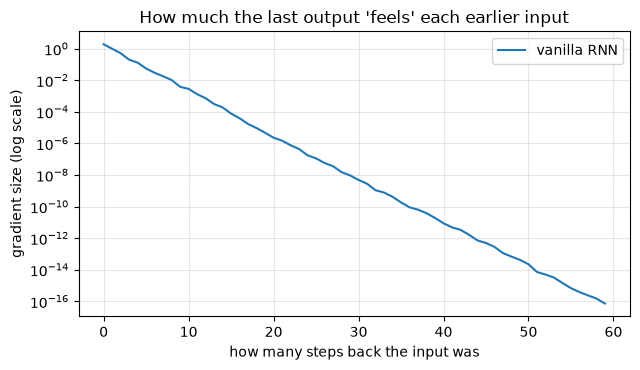

In [9]:
plt.figure(figsize=(6.5, 3.8))
plt.semilogy(g_rnn.numpy(), label="vanilla RNN")
plt.xlabel("how many steps back the input was"); plt.ylabel("gradient size (log scale)")
plt.title("How much the last output 'feels' each earlier input"); plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.show()

### 3.3 Does it matter in practice? A memory test

A vanishing gradient is a warning sign, but the real question is whether the network can still **learn** a long-range task. So let's set it one. Each sequence is a list of random tokens. The **first** token is a clue, 0 or 1, and the label is simply that clue. Everything after it is noise. To succeed, the network must remember the first token all the way to the end, and it classifies using only its final hidden state. By changing the sequence length, we control exactly how far the information has to travel.

In [10]:
def make_task(n, T, seed):
    """Sequences of random tokens 2..9. The FIRST token is 0 or 1, and that is the label."""
    g = torch.Generator().manual_seed(seed)
    x = torch.randint(2, 10, (n, T), generator=g)
    y = torch.randint(0, 2, (n,), generator=g)
    x[:, 0] = y
    return x, y

print(make_task(2, 10, seed=0))

class SeqClassifier(nn.Module):
    def __init__(self, kind="rnn", forget_bias=None):
        super().__init__()
        self.emb = nn.Embedding(10, 16)
        self.rnn = (nn.RNN if kind == "rnn" else nn.LSTM)(16, 32, batch_first=True)
        if forget_bias is not None:          # LSTM only: start with the forget gate open (see Section 4)
            with torch.no_grad():
                for b_ in [self.rnn.bias_ih_l0, self.rnn.bias_hh_l0]:
                    b_[32:64] = forget_bias
        self.out = nn.Linear(32, 2)
    def forward(self, x):
        h, _ = self.rnn(self.emb(x))         # (B, T, 32)
        return self.out(h[:, -1])            # classify from the LAST hidden state only

def run_task(T, seed, **kw):
    Xt, yt = make_task(4000, T, seed=100)    # training sequences
    Xv, yv = make_task(1000, T, seed=200)    # validation sequences
    torch.manual_seed(seed)
    m = SeqClassifier(**kw); opt = torch.optim.Adam(m.parameters(), lr=3e-3)
    for epoch in range(8):
        perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), 64):
            b_ = perm[i:i+64]
            opt.zero_grad(); F.cross_entropy(m(Xt[b_]), yt[b_]).backward(); opt.step()
    with torch.no_grad():
        return (m(Xv).argmax(1) == yv).float().mean().item()

(tensor([[0, 9, 7, 2, 5, 5, 5, 9, 3, 5],
        [1, 4, 6, 9, 8, 2, 2, 6, 4, 3]]), tensor([0, 1]))


The two example sequences start with 0 and 1, and their labels are 0 and 1. Now we train an RNN at four lengths, with 3 different random seeds each, and measure accuracy on 1,000 validation sequences. Guessing would score about 0.5, and each validation sequence is worth 0.001 of accuracy.

In [11]:
LENGTHS, SEEDS = [10, 30, 50, 100], [0, 1, 2]
task_results = {}
for T in LENGTHS:
    accs = [run_task(T, s, kind="rnn") for s in SEEDS]
    task_results[("RNN", T)] = accs
    print(f"vanilla RNN, length {T:>3}: val acc per seed {[round(a_, 3) for a_ in accs]}")
print("one validation sequence is worth", 1 / 1000, "of accuracy; guessing gives about 0.5")

vanilla RNN, length  10: val acc per seed [1.0, 1.0, 1.0]


vanilla RNN, length  30: val acc per seed [0.475, 0.461, 1.0]


vanilla RNN, length  50: val acc per seed [0.511, 0.494, 0.51]


vanilla RNN, length 100: val acc per seed [0.533, 0.518, 0.501]
one validation sequence is worth 0.001 of accuracy; guessing gives about 0.5


At length 10, every seed solves the task perfectly (1.0). At length 30, only one of the three seeds succeeds; the other two score 0.475 and 0.461, no better than guessing. At lengths 50 and 100, every seed fails, with accuracies between 0.494 and 0.533.

The task itself is trivial: "repeat the first token". The RNN fails not because the task is hard, but because the error signal from the end of the sequence cannot reach the first step to teach it what to remember. This is the long-term-dependency problem, measured directly.

> **Key terms**
> - **Long-term dependency:** a relationship between items far apart in a sequence.
> - **Vanishing gradient:** a gradient that shrinks towards zero as it travels back through many steps, so early inputs cannot be learned from.
> - **Exploding gradient:** a gradient that grows uncontrollably as it travels back.

> **Check yourself 3.** Why does the RNN succeed at length 10 but fail at length 50, when the rule to learn ("output the first token") is exactly the same?

## 4. LSTM and GRU: The Intuition Behind Gating Mechanisms *(Extension)*

*This section goes a little deeper than the rest of the note. The key idea, that gates let a network choose what to keep, is worth understanding; the details are optional.*

The vanilla RNN overwrites its entire memory at every step: the new hidden state is a fresh tanh of a mix of input and old memory. The **Long Short-Term Memory (LSTM)** network, designed specifically to solve the problem we just measured, changes this. It keeps a separate memory, the **cell state**, and controls it with **gates**.

A **gate** is a set of numbers between 0 and 1, produced by a sigmoid function, that is multiplied element by element with some other vector. A gate value of 1 lets everything through; 0 blocks everything. The LSTM has three:

- the **forget gate** decides how much of the old cell state to keep;
- the **input gate** decides how much new information to write;
- the **output gate** decides how much of the cell state to reveal as the hidden state.

The crucial change is in how memory is carried forward. Instead of being squashed through tanh at every step, the cell state is updated mostly by **multiplying by the forget gate and adding new information**. If the forget gate stays close to 1, the memory, and the gradient flowing back along it, passes from step to step almost unchanged.

> 🖼 *IMAGE 5.4.2 — The LSTM's Memory Lane.* A single wide LSTM cell drawn as a rounded rectangle on a white background. Across the top runs a thick straight horizontal green line labelled "cell state (long-term memory)", entering on the left as c(t−1) and leaving on the right as c(t). On this line sit two small circles: a "×" circle fed from below by a small gate box labelled "forget gate f (0–1)", and a "+" circle fed from below by a box labelled "input gate × new candidate". Lower in the cell, a thinner orange line carries the hidden state h(t−1) in from the left and h(t) out on the right, with a box labelled "output gate" connecting the cell state down to h(t). The current input x(t) enters from the bottom and feeds all three gate boxes. A callout beside the green line: "if f ≈ 1, memory and gradient flow straight through". Takeaway: the LSTM keeps a protected memory line that gates can preserve across many steps.

### 4.1 The catch: the gate must start open

Here is a detail that is easy to miss. The forget gate is computed with a sigmoid of a weighted sum plus a bias. PyTorch starts all biases at around zero, so at the start of training the forget gate sits at about sigmoid(0):

In [12]:
sig = torch.sigmoid
print(f"forget gate at the start of training (bias 0):  sigmoid(0) = {sig(torch.tensor(0.)).item():.3f}")
print(f"forget gate with bias 1.5 + 1.5 = 3:            sigmoid(3) = {sig(torch.tensor(3.)).item():.3f}")
print(f"memory kept after 40 steps at 0.5 per step:   {0.5 ** 40:.1e}")
print(f"memory kept after 40 steps at 0.953 per step: {sig(torch.tensor(3.)).item() ** 40:.3f}")

forget gate at the start of training (bias 0):  sigmoid(0) = 0.500
forget gate with bias 1.5 + 1.5 = 3:            sigmoid(3) = 0.953
memory kept after 40 steps at 0.5 per step:   9.1e-13
memory kept after 40 steps at 0.953 per step: 0.143


At the default starting point, the forget gate is 0.500: the LSTM keeps only half of its memory per step. After 40 steps that leaves 9.1e-13, the same vanishing as a plain RNN. If instead we set the forget-gate bias so that the gate starts at sigmoid(3) = 0.953, the memory kept after 40 steps is 0.143, enormously more. (Each LSTM has two bias vectors that are added together, so setting each to 1.5 gives a total of 3.) Starting the forget gate open is a well-known practical technique.

Let's test both versions of the LSTM on the same memory task.

In [13]:
for name, kw in [("LSTM (default start)", dict(kind="lstm")),
                 ("LSTM (forget gate open)", dict(kind="lstm", forget_bias=1.5))]:
    for T in LENGTHS:
        accs = [run_task(T, s, **kw) for s in SEEDS]
        task_results[(name, T)] = accs
        print(f"{name:<24} length {T:>3}: val acc per seed {[round(a_, 3) for a_ in accs]}")

LSTM (default start)     length  10: val acc per seed [1.0, 1.0, 1.0]


LSTM (default start)     length  30: val acc per seed [0.502, 0.495, 0.471]


LSTM (default start)     length  50: val acc per seed [0.506, 0.511, 0.505]


LSTM (default start)     length 100: val acc per seed [0.523, 0.506, 0.528]


LSTM (forget gate open)  length  10: val acc per seed [1.0, 1.0, 1.0]


LSTM (forget gate open)  length  30: val acc per seed [1.0, 1.0, 1.0]


LSTM (forget gate open)  length  50: val acc per seed [1.0, 1.0, 1.0]


LSTM (forget gate open)  length 100: val acc per seed [1.0, 1.0, 1.0]


The results are striking:

- The **default LSTM** does no better than the vanilla RNN. It solves length 10, but fails at length 30 on all three seeds (0.471 to 0.502), and at every longer length.
- The **LSTM with its forget gate open** scores 1.0 on every seed, at every length, all the way to 100.

The plot shows all three models; each line is the average over seeds, and the faint dots are individual seeds.

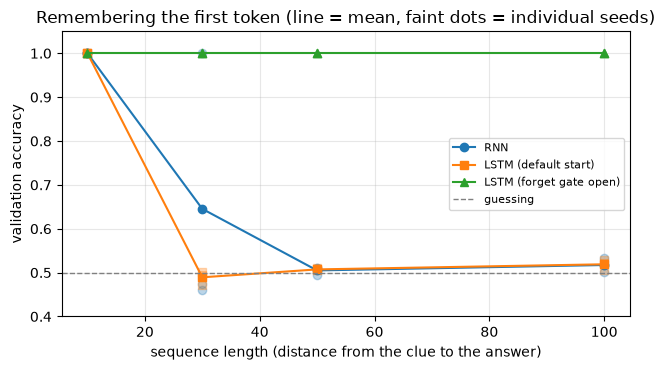

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for (name, marker) in [("RNN", "o"), ("LSTM (default start)", "s"), ("LSTM (forget gate open)", "^")]:
    means = [np.mean(task_results[(name, T)]) for T in LENGTHS]
    ax.plot(LENGTHS, means, marker=marker, label=name)
    for T in LENGTHS:
        ax.scatter([T] * len(SEEDS), task_results[(name, T)], marker=marker, alpha=0.3, color=ax.lines[-1].get_color())
ax.axhline(0.5, color="grey", ls="--", lw=1, label="guessing")
ax.set_xlabel("sequence length (distance from the clue to the answer)"); ax.set_ylabel("validation accuracy")
ax.set_title("Remembering the first token (line = mean, faint dots = individual seeds)")
ax.set_ylim(0.4, 1.05); ax.grid(alpha=0.3); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

The gradient measurement from Section 3.1 tells the same story from the inside:

In [15]:
def open_lstm():
    lstm = nn.LSTM(16, 32, batch_first=True)
    with torch.no_grad():
        for b_ in [lstm.bias_ih_l0, lstm.bias_hh_l0]:
            b_[32:64] = 1.5
    return RNNWrap(lstm)

g_lstm = gradient_reach(lambda: RNNWrap(nn.LSTM(16, 32, batch_first=True)))
g_open = gradient_reach(open_lstm)
for k in [10, 20, 40]:
    print(f"{k:>2} steps back:  RNN {g_rnn[k].item():.1e} | LSTM {g_lstm[k].item():.1e} | LSTM open {g_open[k].item():.1e}")

10 steps back:  RNN 2.9e-03 | LSTM 5.0e-03 | LSTM open 1.8e-01
20 steps back:  RNN 2.3e-06 | LSTM 5.4e-05 | LSTM open 2.1e-01
40 steps back:  RNN 8.8e-12 | LSTM 6.1e-09 | LSTM open 3.0e-01


Forty steps back, the gradient is 8.8e-12 for the RNN, 6.1e-09 for the default LSTM, and 0.30 for the open-gate LSTM. The open forget gate keeps the gradient path alive.

So the honest summary is: **gates make long-term memory possible, but they have to be used that way.** An LSTM's architecture allows memory to persist; whether it does depends on the gate values, which are learned, and which need a good starting point.

The **Gated Recurrent Unit (GRU)** is a simplified relative of the LSTM. It merges the cell state and hidden state and uses two gates instead of three, so it is a little cheaper. With an input size of 16 and a hidden size of 32, a vanilla RNN has 1,600 parameters, a GRU 4,800 and an LSTM 6,400: each gate needs its own weights.

In [16]:
print("parameters with input 16 and hidden 32:")
for name, cell in [("RNN", nn.RNN(16, 32)), ("GRU", nn.GRU(16, 32)), ("LSTM", nn.LSTM(16, 32))]:
    print(f"  {name:<5} {sum(p.numel() for p in cell.parameters()):>5}")

parameters with input 16 and hidden 32:
  RNN    1600
  GRU    4800
  LSTM   6400


> **Key terms**
> - **LSTM (Long Short-Term Memory):** a recurrent network with a protected cell state controlled by forget, input and output gates.
> - **GRU (Gated Recurrent Unit):** a simpler gated recurrent network with two gates.
> - **Gate:** a vector of values between 0 and 1 (from a sigmoid) that scales another vector, letting information through or blocking it.
> - **Cell state:** the LSTM's long-term memory line.

> **Check yourself 4.** The default LSTM failed the length-30 task even though its architecture is designed for long memory. In one sentence, why?

## 5. The Limitations of Recurrent Processing

If an LSTM with a well-set forget gate can carry a fact across 100 steps, why did the field move on? Because remembering *one* fact is not the only requirement. Real language tasks expose two deeper limitations that no choice of gates can remove.

**Limitation 1: everything must squeeze through one fixed-size memory.** However long the sequence is, the RNN carries forward only its hidden state.

In [17]:
torch.manual_seed(0)
cell = nn.RNN(16, 32, batch_first=True)
for T in [10, 1000]:
    out, h_final = cell(torch.randn(1, T, 16))
    print(f"T={T:>4}: everything the RNN carries forward is h_final {tuple(h_final.shape)}")
    print(f"        steps that must run one after another: {T}")
X = torch.randn(1000, 32)
scores = X @ X.T                  # every position compared with every other, in ONE matrix multiplication
print("all pairwise scores for 1000 positions:", tuple(scores.shape), "computed in a single operation")

T=  10: everything the RNN carries forward is h_final (1, 1, 32)
        steps that must run one after another: 10
T=1000: everything the RNN carries forward is h_final (1, 1, 32)
        steps that must run one after another: 1000
all pairwise scores for 1000 positions: (1000, 1000) computed in a single operation


With a hidden size of 32, the RNN carries forward a `(1, 1, 32)` state after 10 steps, and exactly the same 32 numbers after 1,000 steps. Every fact from a 1,000-word document (names, dates, who did what to whom) must be compressed into those 32 numbers before the end. Adding facts means overwriting others. This is called the **information bottleneck**.

**Limitation 2: the steps must run one after another.** To compute the hidden state at step 1,000, the RNN needs the state at step 999, which needs step 998, and so on: 1,000 steps that cannot be done at the same time. Modern hardware such as GPUs is fast precisely because it does thousands of calculations *in parallel*. A sequential loop wastes most of that power, which makes RNNs slow to train on large datasets.

Compare the last line of the output. Comparing every position with every other position, for all 1,000 positions, is a single matrix multiplication producing a `(1000, 1000)` grid of scores. All of it can be computed at once. That operation is the core of attention.

## 6. From Sequential Processing to Attention

**Attention** takes a completely different approach. Instead of passing information along a chain, step by step, it lets each position **look directly at every other position** and decide how much to take from each one.

Here is the idea in one picture. To build its representation, the last word in a sentence asks a question, its **query**. Every word in the sentence offers a **key**, a description of what it contains, and a **value**, the information it can contribute. The query is compared with every key to produce a score; the scores are turned into weights that sum to 1 (with softmax); and the result is a **weighted average of the values**. A word that is relevant to the query gets a large weight, *however far away it is*.

> 🖼 *IMAGE 5.4.3 — Chain vs. Direct Access.* Two horizontal panels on a white background, each with the same six word boxes in a row: "The", "film", "…", "…", "director", "was". Top panel titled "RNN: information travels along a chain": orange arrows link each box to the next, left to right, and a long faint red arrow underneath points from "was" back to "film", labelled "signal must pass through every step in between". Bottom panel titled "Attention: every word can look at every word": from "was", six curved blue lines of different thickness fan out to all six boxes, with the line to "film" drawn thickest and labelled "high weight", and the lines to "…" thin, labelled "low weight". Caption beneath the bottom panel: "distance doesn't matter; relevance does". Takeaway: attention replaces a long chain of steps with direct, weighted connections.

Let's build the smallest possible version of this, a single attention step in which the last position attends to all 60 positions, and run the same gradient measurement as in Section 3.1. We will study queries, keys and values properly in Module 6; for now, watch what happens to the gradient.

In [18]:
class TinyAttention(nn.Module):
    """The last position looks directly at every position and takes a weighted average."""
    def __init__(self, d=16, h=32):
        super().__init__()
        self.q, self.k, self.v = nn.Linear(d, h), nn.Linear(d, h), nn.Linear(d, h)
    def forward(self, x):                                  # x: (1, T, d)
        q = self.q(x[:, -1:])                              # (1, 1, h) a "question" from the last position
        k, v = self.k(x), self.v(x)                        # (1, T, h) each position's "label" and "content"
        w = torch.softmax(q @ k.transpose(1, 2) / k.shape[-1] ** 0.5, dim=-1)   # (1, 1, T) weights sum to 1
        self.weights = w.detach()
        out = w @ v                                        # (1, 1, h) weighted average of contents
        return out.expand(-1, x.shape[1], -1)              # same shape as an RNN's output, for comparison

g_att = gradient_reach(TinyAttention)
for k in [0, 10, 20, 40, 59]:
    print(f"{k:>2} steps back: attention {g_att[k].item():.1e} | RNN {g_rnn[k].item():.1e}")

 0 steps back: attention 2.4e-01 | RNN 1.9e+00
10 steps back: attention 5.2e-02 | RNN 2.9e-03
20 steps back: attention 5.4e-02 | RNN 2.3e-06
40 steps back: attention 4.0e-02 | RNN 8.8e-12
59 steps back: attention 3.9e-02 | RNN 7.3e-17


Through attention, the gradient reaching an input 59 steps back is 3.9e-02, about the same as for an input 10 steps back (5.2e-02). Through the RNN, the input 59 steps back receives 7.3e-17. The most recent position gets a larger gradient under attention (2.4e-01) only because it also supplies the query. Here are all four measurements together:

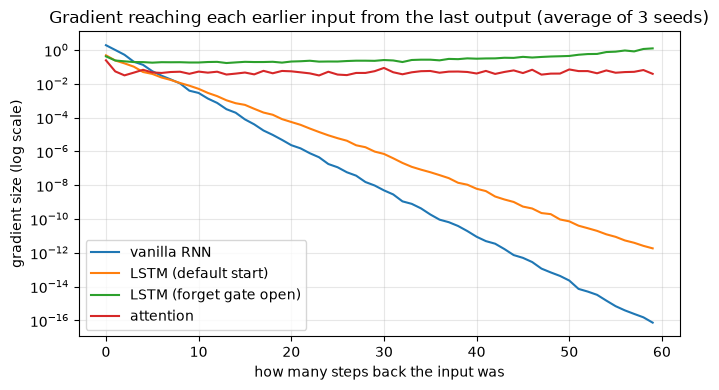

In [19]:
plt.figure(figsize=(7, 4))
for g, lab in [(g_rnn, "vanilla RNN"), (g_lstm, "LSTM (default start)"),
               (g_open, "LSTM (forget gate open)"), (g_att, "attention")]:
    plt.semilogy(g.numpy(), label=lab)
plt.xlabel("how many steps back the input was"); plt.ylabel("gradient size (log scale)")
plt.title("Gradient reaching each earlier input from the last output (average of 3 seeds)")
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()

The picture summarises this whole note:

- The **vanilla RNN** (blue) and **default LSTM** (orange) fall in straight lines: their gradients shrink by a constant factor per step.
- The **open-gate LSTM** (green) keeps its gradient, and even grows slightly towards the far past, but it still has the fixed-size bottleneck and still has to process one step at a time.
- **Attention** (red) is flat: every input is one step away from the output, so distance simply does not matter.

Attention solves all three problems at once:

1. **No long chain:** every position connects directly to every other, so gradients do not have to survive many multiplications.
2. **No single bottleneck:** each position keeps its own vector, and any position can draw on any other, so information does not all have to fit into one hidden state.
3. **Parallel computation:** all the comparisons are matrix multiplications that run at once on a GPU.

It also gives us what Note 5.3 was missing: **contextual representations**. When "bank" attends to "river", or "good" attends to "not", its new vector reflects its surroundings.

Attention has a price. Comparing every position with every other means the number of comparisons grows with the *square* of the sequence length. For 1,000 positions, that was a `(1000, 1000)` grid, a million scores. You will meet this cost, and how it is managed, in Module 6.

> **Common mistake:** concluding that RNNs "cannot remember". As you measured, a well-initialised LSTM carried a fact across 100 steps perfectly. The reasons attention replaced recurrence for language are the fixed-size bottleneck and sequential computation, together with attention's direct access to every position.

> **Key terms**
> - **Attention:** a mechanism in which each position computes a weighted average of other positions' information, with weights based on relevance.
> - **Query, key, value:** what a position is looking for, what each position offers as a description, and the information each position contributes.
> - **Information bottleneck:** forcing all information through a fixed-size representation.
> - **Parallel computation:** performing many calculations at the same time instead of one after another.

> **Check yourself 5.** Give two reasons, other than vanishing gradients, why processing a 10,000-word document with an RNN is difficult.

## Putting It All Together

Sequences carry meaning in their **order**, but a bag of words, or an average of embeddings, is order-blind: "dog bites man" and "man bites dog" got identical representations (cosine 1.0).

An **RNN** reads one item at a time and carries a **hidden state** forward, so order changes its memory (final-state cosine 0.2831). But to learn, its gradient must travel back through every step, and it is multiplied by a shrinking factor each time. Forty steps back, it had fallen to 8.8e-12. On a task as simple as "remember the first token", the RNN succeeded at length 10 and failed beyond 30.

The **LSTM** adds a protected cell state controlled by **gates**. With its forget gate starting open, it solved the task at every length up to 100, and its gradient no longer vanished (0.30 forty steps back). With the default start, it failed just like the RNN. Gates make long memory *possible*; they do not guarantee it.

Even a good LSTM keeps two limitations: all information must pass through a **fixed-size hidden state**, 32 numbers whether the sequence has 10 steps or 1,000, and the steps must run **one after another**. **Attention** removes both. Each position looks directly at every other position and takes a relevance-weighted average, all in parallel. Its gradient reach was flat across all 60 positions. That idea, developed fully, is the **Transformer**, the subject of Module 6.

> 🖼 *IMAGE 5.4.4 — The Road to Attention.* A left-to-right timeline of four stepping-stone panels on a white background, connected by arrows. Panel 1 "Bag of words / averaging": a jumbled pile of word tiles, caption "order-blind". Panel 2 "RNN": a chain of three blue boxes passing an orange memory arrow, caption "order-aware, but memory fades". Panel 3 "LSTM": the chain with a green protected memory line on top and small gate symbols, caption "gates can keep memory, but one-at-a-time and through a fixed-size state". Panel 4 "Attention": six word boxes with blue curved lines connecting each to all others, caption "direct, parallel, contextual". Beneath the timeline, an arrow labelled "→ Transformers (Module 6)". Takeaway: each step fixed the previous step's main limitation, leading to attention.

## Summary

- In sequences, order carries meaning. Bags of words and averaged embeddings are order-blind.
- An **RNN** processes one item at a time with the rule h_t = tanh(W_x x_t + W_h h_(t−1) + b), using the same weights at every step and carrying a **hidden state** forward. It is order-aware.
- Backpropagating through many steps multiplies the gradient by similar factors repeatedly, so it **vanishes** (or explodes). We measured it falling to 8.8e-12 forty steps back.
- On a "remember the first token" task, a vanilla RNN failed beyond length 30, even though the rule never changed.
- **LSTMs** (and GRUs) add **gates** and a protected memory. With the forget gate starting open, an LSTM solved the task up to length 100; with the default start, it failed like the RNN.
- Recurrent models still squeeze everything through a **fixed-size state** and must compute **sequentially**.
- **Attention** lets every position look directly at every other position and take a weighted average, in parallel. Its gradient reach is flat with distance. It is the core of the Transformer.

## Glossary

| Term | Meaning |
|---|---|
| Sequence | An ordered list of items in which order carries meaning. |
| Bag of words | A representation that records which words appear, ignoring order. |
| Order-blind | Producing the same result regardless of input order. |
| RNN (recurrent neural network) | A network that reads a sequence one step at a time, carrying a hidden state forward. |
| Hidden state | The RNN's running memory vector. |
| Unrolling | Viewing an RNN as one copy of its cell per time step. |
| tanh | A function that squashes values into the range −1 to +1. |
| Long-term dependency | A relationship between items far apart in a sequence. |
| Vanishing / exploding gradient | Gradients that shrink to nothing / grow out of control across many steps. |
| LSTM | Long Short-Term Memory: an RNN with a gated, protected cell state. |
| GRU | Gated Recurrent Unit: a simpler gated RNN with two gates. |
| Gate | A vector of values between 0 and 1 that controls how much information passes. |
| Forget gate | The LSTM gate that decides how much old memory to keep. |
| Cell state | The LSTM's long-term memory line. |
| Information bottleneck | Forcing all information through a fixed-size representation. |
| Attention | Each position takes a relevance-weighted average of other positions' information. |
| Query / key / value | What a position looks for / what each position offers / what each position contributes. |
| Parallel computation | Doing many calculations at once rather than in sequence. |

## Answers to Check Yourself

**1.** Many answers work. For example: the steps of a recipe (mix then bake is not the same as bake then mix), a phone number or PIN, a sequence of moves in a game, or a patient's symptoms appearing in a particular order.

**2.** 32 numbers in both cases. The hidden state has a fixed size, whatever the length of the sequence. That is the information bottleneck of Section 5.

**3.** The rule is the same, but the distance the learning signal must travel is not. At length 50, the gradient from the final output must pass back through 49 steps before reaching the first token, and it shrinks at every step, so almost nothing arrives to teach the network what it should have stored. At length 10, enough of the gradient survives.

**4.** Its forget gate started at about 0.5, so it kept only half its memory per step, and the memory (and gradient) vanished almost as fast as in a plain RNN, before the gates could learn to stay open.

**5.** First, everything must be compressed into a fixed-size hidden state, so facts from early in the document are overwritten by later ones (the information bottleneck). Second, the 10,000 steps must be computed one after another, which makes training slow and wastes the parallel power of modern hardware.